# Eco-Concrete Strength Modeling (Notebook 2)
## Cross-Validation, Tuning, and Publication-Ready Outputs

**Goal:** Make your modeling results **more defensible** by adding cross-validation, basic hyperparameter tuning, and exportable figures/tables for the paper + GitHub

### What this notebook adds:
1. Robust data loading (Local or Colab + Google Drive)
2. Cross-validation evaluation (R², MAE)
3. Simple hyperparameter tuning (Random Forest + Gradient Boosting)
4. “Holdout test” evaluation on an untouched test set
5. Publication-ready outputs:
   - figures saved to `./figures/`
   - results tables saved to `./outputs/`
6. A sustainability proxy section

---
## Expected folder structure example (recommended)
If running locally or in a Drive-synced folder:
```
Research Project/
  notebooks/
    02_eco_concrete_cv_tuning_outputs.ipynb
  data/
    Concrete_Data.csv
  figures/
  outputs/
  src/
```


In [ ]:
# Install dependencies
!pip -q install scikit-learn pandas numpy matplotlib
# Scikit-learn is for AI model/running
# Pandas is for handling large data sets
# Numpy (100 rows or less) is for data handling and calculations
# Matplotlib is for regression and modeling
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Necessary for later steps
from sklearn.model_selection import train_test_split, KFold, cross_validate, GridSearchCV
from sklearn.metrics import r2_score, mean_absolute_error, make_scorer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.inspection import permutation_importance

# Ensures repeatability
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Create 2 additional folders with OS library
FIG_DIR = "figures"
OUT_DIR = "outputs"
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(OUT_DIR, exist_ok=True)


## 1) Data loading options (Local vs Colab)

### Option A: relative `data/` folder (local or Drive-synced)
Keep your CSV here:
```
./data/Concrete_Data.csv
```

### Option B: Colab + Google Drive
Mount Drive, then set `BASE_DIR` to your Drive path (example below).

> Tip: In Colab, Drive paths look like `/content/drive/MyDrive/...`


In [ ]:
# If running in Google Colab, this code mounts the Drive
from google.colab import drive
drive.mount('/content/drive')

# Alternative: local/drive-synced relative folder
# DATA_DIR = "data"

from pathlib import Path
import pandas as pd


# Sets the location that receives outputs and figures from this notebook
BASE_DIR = Path("/content/drive/MyDrive/Indigo Research Project")

DATA_DIR = BASE_DIR / "data"
FIG_DIR = BASE_DIR / "figures"
OUT_DIR = BASE_DIR / "outputs"

DATA_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Prints results for viewing and troubleshooting
print("BASE_DIR:", BASE_DIR)
print("DATA_DIR:", DATA_DIR)
print("FIG_DIR:", FIG_DIR)
print("OUT_DIR:", OUT_DIR)

print("DATA_DIR exists?", DATA_DIR.exists())

# Ensures correct CSV is selected
possible_csv_names = [
    "concrete_data.csv",
    "Concrete_Data.csv",
    "Concrete_Data_Yeh.csv"
]

# Auto-detect the CSV(s) in DATA_DIR
csv_path = None
for name in possible_csv_names:
    candidate = DATA_DIR / name
    if candidate.exists():
        csv_path = candidate
        break

# Used incase of directory error
if csv_path is None:
    available_csvs = list(DATA_DIR.glob("*.csv"))
    print("CSV files found in DATA_DIR:")
    for file in available_csvs:
        print(file.name)
    raise FileNotFoundError(
        "Could not find concrete_data.csv or Concrete_Data.csv in the data folder. "
        "Please upload the baseline concrete CSV into the Drive data folder."
    )

# Loads and prints CSV
df = pd.read_csv(csv_path)

df.columns = df.columns.str.strip()

print("Loaded dataset:", csv_path)
print("Shape:", df.shape)

df.head()

Mounted at /content/drive
BASE_DIR: /content/drive/MyDrive/Indigo Research Project
DATA_DIR: /content/drive/MyDrive/Indigo Research Project/data
FIG_DIR: /content/drive/MyDrive/Indigo Research Project/figures
OUT_DIR: /content/drive/MyDrive/Indigo Research Project/outputs
DATA_DIR exists? True
Loaded dataset: /content/drive/MyDrive/Indigo Research Project/data/concrete_data.csv
Shape: (1030, 9)


,cement,blast_furnace_slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate,age,concrete_compressive_strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


## 2) Clean column names + identify the target

We normalize column names and auto-detect the compressive strength target column.


In [ ]:
# Normalizes column names
def normalize_col(c: str) -> str:
    c = c.strip().lower()
    c = c.replace(" ", "_").replace("-", "_")
    c = c.replace("(", "").replace(")", "")
    while "__" in c:
        c = c.replace("__", "_")
    return c

# Prevents original dataframe from being modified
df = df.copy()
# Continues to normalize
df.columns = [normalize_col(c) for c in df.columns]
# Searches for possible target columns (strength, compressive)
possible_targets = [c for c in df.columns if "strength" in c or "compressive" in c]
print("Possible target columns:", possible_targets)

# Looks for mpa and defines target column
TARGET_COL = None
for c in possible_targets:
    if "mpa" in c:
        TARGET_COL = c
        break
if TARGET_COL is None and len(possible_targets) == 1:
    TARGET_COL = possible_targets[0]
if TARGET_COL is None and "concrete_compressive_strength" in df.columns:
    TARGET_COL = "concrete_compressive_strength"

if TARGET_COL is None:
    raise ValueError("Could not auto-detect TARGET_COL. Please set it manually.")

print("Using TARGET_COL =", TARGET_COL)

# Checks for leftover strings, converts strings to numerics
for c in df.columns:
    if c == TARGET_COL:
        continue
    if df[c].dtype == "object":
        df[c] = pd.to_numeric(df[c], errors="coerce")

df = df.dropna(subset=[TARGET_COL]).reset_index(drop=True)

numeric_cols = [c for c in df.columns if pd.api.types.is_numeric_dtype(df[c])]
feature_cols = [c for c in numeric_cols if c != TARGET_COL]

# x is the numeric, y is the value
X = df[feature_cols].copy()
y = df[TARGET_COL].copy()

print("Rows:", len(df))
print("Features:", feature_cols)


Possible target columns: ['concrete_compressive_strength']
Using TARGET_COL = concrete_compressive_strength
Rows: 1030
Features: ['cement', 'blast_furnace_slag', 'fly_ash', 'water', 'superplasticizer', 'coarse_aggregate', 'fine_aggregate', 'age']


## 3) Train/test split (holdout test set)

All cross-validation and tuning happen only on the training set.


In [ ]:
# Splits x and y into, 80% training, 20% testing (what the data is based on).
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)
print("Train:", X_train.shape, "Test:", X_test.shape)


Train: (824, 8) Test: (206, 8)


## 4) Cross-validation baseline evaluation (5-fold)

We compute mean ± STD for **R²** and **MAE** on the training set.


In [ ]:
# Does baseline evaluation of the 3 models
    # Takes the mean, R^2, and mean absolute error + the standard deviation of each
def mae_scorer():
    return make_scorer(mean_absolute_error, greater_is_better=False)

# Initiates 5 fold cross-validation for machine learning
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Refer to Notebook 1 for variable explanation
models = {
    "LinearRegression": Pipeline([("scaler", StandardScaler()), ("lr", LinearRegression())]),
    "RandomForest": RandomForestRegressor(n_estimators=400, random_state=RANDOM_STATE, n_jobs=-1),
    "GradientBoosting": GradientBoostingRegressor(random_state=RANDOM_STATE),
}

rows = []
for name, model in models.items():
    scores = cross_validate(
        model, X_train, y_train,
        cv=cv,
        scoring={"r2": "r2", "mae": mae_scorer()},
        return_train_score=False
    )
    rows.append({
        "model": name,
        "cv_r2_mean": float(np.mean(scores["test_r2"])),
        "cv_r2_std": float(np.std(scores["test_r2"])),
        "cv_mae_mean": float(-np.mean(scores["test_mae"])),
        "cv_mae_std": float(np.std(-scores["test_mae"])),
    })

# Creates cross validation performance, compares the models
cv_df = pd.DataFrame(rows).sort_values("cv_r2_mean", ascending=False)
cv_df


,model,cv_r2_mean,cv_r2_std,cv_mae_mean,cv_mae_std
1,RandomForest,0.900023,0.016448,3.673030,0.240467
2,GradientBoosting,0.891328,0.017048,3.981997,0.294528
0,LinearRegression,0.597135,0.047330,8.421618,0.406350


In [ ]:
# Save cross validation table to CSV
cv_path = os.path.join(OUT_DIR, "cv_summary.csv")
cv_df.to_csv(cv_path, index=False)
print("Saved:", cv_path)


Saved: /content/drive/MyDrive/Indigo Research Project/outputs/cv_summary.csv


## 5) Hyperparameter tuning (small grid search)

This is enough to justify that you tried reasonable settings without overfitting.


In [ ]:
# Initializes random forest model
rf = RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1)

# Setting up a random forest hyperparameter grid for tuning
rf_grid = {
    # Number of trees
    "n_estimators": [300, 600],
    # Maximum depth each individual decision tree (growth limit)
    "max_depth": [None, 8, 14],
    # Minimum number of samples in final prediction of each tree
    "min_samples_leaf": [1, 2, 4],
}

# Print out best parameters and best cross-validation score
rf_search = GridSearchCV(rf, rf_grid, cv=cv, scoring="r2", n_jobs=-1)
rf_search.fit(X_train, y_train)

# Prints results
print("Best RF params:", rf_search.best_params_)
print("Best RF CV R²:", rf_search.best_score_)


Best RF params: {'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 300}
Best RF CV R²: 0.9001438482877994


In [ ]:
from sklearn.ensemble import GradientBoostingRegressor

# Initializes gradient boosting regressor
gbr = GradientBoostingRegressor(random_state=RANDOM_STATE)

# Same processes as previous cell
gbr_grid = {
    # Number of boosting stages or sequential decision trees
    "n_estimators": [200, 400],
    # Shrinkage factor, contribution of each individual tree
    "learning_rate": [0.03, 0.07, 0.1],
    # Maximum depth of each individual regression tree
    # Controls complexity of each learner
    "max_depth": [2, 3],
}

# Print out best parameters and best cross-validation score
gbr_search = GridSearchCV(gbr, gbr_grid, cv=cv, scoring="r2", n_jobs=-1)
gbr_search.fit(X_train, y_train)

# Prints results
print("Best GBR params:", gbr_search.best_params_)
print("Best GBR CV R²:", gbr_search.best_score_)

Best GBR params: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 400}
Best GBR CV R²: 0.9155329529072549


## 6) Final test-set evaluation

We evaluate the tuned models on the holdout test set and save a results table.


In [ ]:
# Using models on untouched test set, compares the training set to the test set
def eval_on_test(name, model):
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    return {
        "model": name,
        "test_r2": float(r2_score(y_test, pred)),
        "test_mae": float(mean_absolute_error(y_test, pred)),
        "pred": pred,
        "fitted": model
    }

# Defines final_models
final_models = {
    "LinearRegression": Pipeline([("scaler", StandardScaler()), ("lr", LinearRegression())]),
    "RandomForest_tuned": rf_search.best_estimator_,
    "GradientBoosting_tuned": gbr_search.best_estimator_,
}

# Creating a CSV and saving best R^2 based on the 3 models (ranked)
final_rows = []
final_store = {}
for name, m in final_models.items():
    out = eval_on_test(name, m)
    final_rows.append({k: out[k] for k in ["model", "test_r2", "test_mae"]})
    final_store[name] = out

final_df = pd.DataFrame(final_rows).sort_values("test_r2", ascending=False)
final_df


,model,test_r2,test_mae
2,GradientBoosting_tuned,0.919526,3.121004
1,RandomForest_tuned,0.880857,3.788964
0,LinearRegression,0.627553,7.745559


In [ ]:
# Saves CSV to outputs
final_path = os.path.join(OUT_DIR, "test_set_results.csv")
final_df.to_csv(final_path, index=False)
print("Saved:", final_path)


Saved: /content/drive/MyDrive/Indigo Research Project/outputs/test_set_results.csv


## 7) Save publication-ready figures

Predicted vs Actual and Feature Importance plots saved into `figures/`.


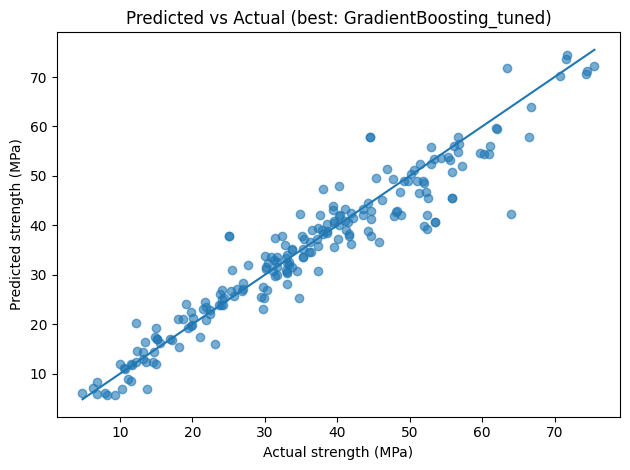

Saved: /content/drive/MyDrive/Indigo Research Project/figures/pred_vs_actual_GradientBoosting_tuned.png


In [ ]:
# Saves figures (best models) to figures directory
best_name = final_df.iloc[0]["model"]
best = final_store[best_name]
best_model = best["fitted"]
y_pred = best["pred"]

# Creates a scatterplot comparing predicted v actual compressive strength
plt.figure()
plt.scatter(y_test, y_pred, alpha=0.6)
plt.xlabel("Actual strength (MPa)")
plt.ylabel("Predicted strength (MPa)")
plt.title(f"Predicted vs Actual (best: {best_name})")

mn = min(y_test.min(), y_pred.min())
mx = max(y_test.max(), y_pred.max())
plt.plot([mn, mx], [mn, mx])
plt.tight_layout()

# Saves figure and prints
fig_path = os.path.join(FIG_DIR, f"pred_vs_actual_{best_name}.png")
plt.savefig(fig_path, dpi=200)
plt.show()
print("Saved:", fig_path)


**Predicted vs Actual Scatterplot:** While inaccurate predictions and outliers exist, the Gradient Boosting model seems to cluster around the plotted line, indicating reasonable model prediction accuracy with few outliers.

Saved: /content/drive/MyDrive/Indigo Research Project/outputs/permutation_importance_GradientBoosting_tuned.csv


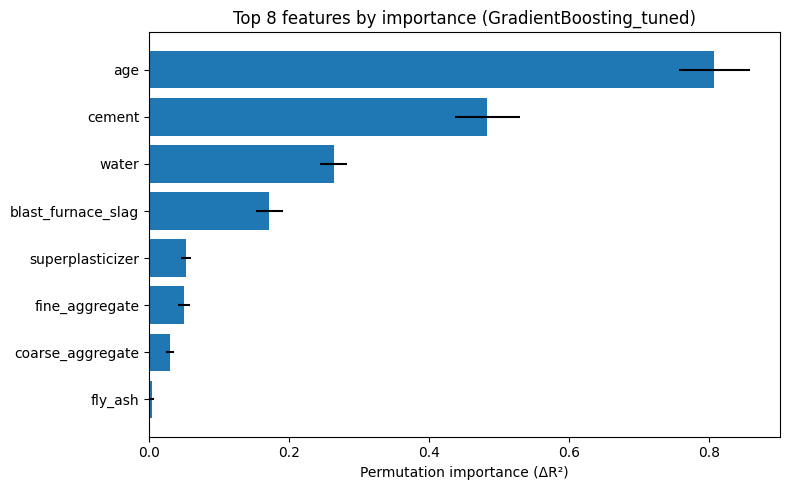

Saved: /content/drive/MyDrive/Indigo Research Project/figures/feature_importance_GradientBoosting_tuned.png


,feature,importance_mean,importance_std
7,age,0.806979,0.050836
0,cement,0.482777,0.046296
3,water,0.263746,0.019052
1,blast_furnace_slag,0.171511,0.019116
4,superplasticizer,0.052413,0.007017
6,fine_aggregate,0.049701,0.008414
5,coarse_aggregate,0.030050,0.005563
2,fly_ash,0.004214,0.002632


In [ ]:
# For the best model, what is the best features of the model?
perm = permutation_importance(
    best_model, X_test, y_test,
    # Ensures results are accurate, computationally expensive as n_repeats increases
    n_repeats=20,
    random_state=RANDOM_STATE,
    scoring="r2"
)

# Plots the importance of each feature found in previous code ^
imp = pd.DataFrame({
    "feature": feature_cols,
    "importance_mean": perm.importances_mean,
    "importance_std": perm.importances_std
}).sort_values("importance_mean", ascending=False)

# Saves permutation importance graph to a CSV file
imp_path = os.path.join(OUT_DIR, f"permutation_importance_{best_name}.csv")
imp.to_csv(imp_path, index=False)
print("Saved:", imp_path)

# Number of variables considered
top_k = min(12, len(feature_cols))
# Takes variables and reverses the horizontal bar order
top = imp.head(top_k).iloc[::-1]

# Plots and saves tabled data on feature importance
plt.figure(figsize=(8, 5))
plt.barh(top["feature"], top["importance_mean"], xerr=top["importance_std"])
plt.xlabel("Permutation importance (ΔR²)")
plt.title(f"Top {top_k} features by importance ({best_name})")
plt.tight_layout()

imp_fig = os.path.join(FIG_DIR, f"feature_importance_{best_name}.png")
plt.savefig(imp_fig, dpi=200)
plt.show()
print("Saved:", imp_fig)

imp.head(12)


**Feature Importance Bar Graph:** Age, cement, and water seem to be the most important features when considering concrete compressive strength, as in they have the greatest effect. This graph matches real-world observations, but does not show the relationship between the feature and the compressive strength of a mixture. Thus, graphs such as the correlation heatmap can be used alongside feature importance to better understand these variables.

## 8) Sustainability layer (CO₂ + cost proxies)

**Important:** The current dataset does *not* include CO₂ emissions or cost.  
To determine sustainability, we create *proxies* from mixture composition.

### How to use this section responsibly
- Treat these as **scenario estimates**, not ground-truth lifecycle assessments.
- Use **literature/CSI** sources to justify the factors you pick.
- Label all plots as proxy analysis unless all values are supported by literature/CSI sources

### Simple proxy approach
Estimate emissions as:
- `CO2_kg = sum_i (mass_i_kg_per_m3 * factor_i_kgCO2_per_kg)`
- `USD_kg = sum_i (mass_i_kg_per_m3 * factor_i_kgUSD_per_kg)`

The current values are defined by literature results and market value estimations as of June 2026.

In [ ]:
# Note
    # Current values should be defined or replaced by relevant literature results
    # Current calculations uses GGBFS and natural aggregate data
# CO2 measured in kg CO₂e per kg of material
# Formula determined by material amount in kg/m³ multiplied by factor in kg CO₂e/kg
CO2_FACTORS = {
    "cement": 2614.5,
    "blast_furnace_slag": 393.6586,
    "fly_ash": 314.65,
    "water": 0.196,
    "superplasticizer": 300,
    "coarse_aggregate": 19.05,
    "fine_aggregate": 6.76,
}

# Cost measured in USD per kg of material
# Formula determined by material amount in kg/m³ multiplied by factor in USD/kg
COST_FACTORS = {
    "cement": 226.80,
    "blast_furnace_slag": 148.65,
    "fly_ash": 273.42,
    "water": 9.60,
    "superplasticizer": 963.84,
    "coarse_aggregate": 24.38,
    "fine_aggregate": 20.80,
}

FEATURE_MAP = {
    "cement": "cement",
    "blast_furnace_slag": "blast_furnace_slag",
    "fly_ash": "fly_ash",
    "water": "water",
    "superplasticizer": "superplasticizer",
    "coarse_aggregate": "coarse_aggregate",
    "fine_aggregate": "fine_aggregate",
}

# Computes trade off between CO2/cost and compressive strength
def compute_proxy(df_in: pd.DataFrame, factors: dict, feature_map: dict) -> pd.Series:
    total = np.zeros(len(df_in), dtype=float)
    for col, key in feature_map.items():
        if col in df_in.columns and key in factors:
            total += df_in[col].values * float(factors[key])
    return pd.Series(total, index=df_in.index)

df_proxy = df.copy()
df_proxy["co2_proxy_kg"] = compute_proxy(df_proxy, CO2_FACTORS, FEATURE_MAP)
df_proxy["cost_proxy_USD"] = compute_proxy(df_proxy, COST_FACTORS, FEATURE_MAP)
df_proxy["pred_strength_mpa"] = best_model.predict(df_proxy[feature_cols])

df_proxy[["pred_strength_mpa", "co2_proxy_kg", "cost_proxy_USD"]].describe().T


,count,mean,std,min,25%,50%,75%,max
pred_strength_mpa,1030.0,35.676538,16.320589,2.513019,24.137611,35.163618,44.558347,8.153978e+01
co2_proxy_kg,1030.0,806913.966899,257342.614450,350211.667800,593878.622000,774754.220350,983831.048800,1.437439e+06
cost_proxy_USD,1030.0,137103.247764,21940.533638,88938.910000,122040.221000,136063.306000,150546.604500,1.944061e+05


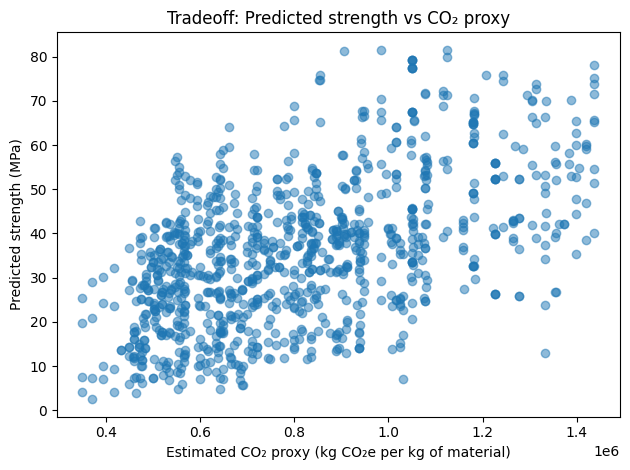

Saved: /content/drive/MyDrive/Indigo Research Project/figures/tradeoff_strength_vs_co2_proxy.png


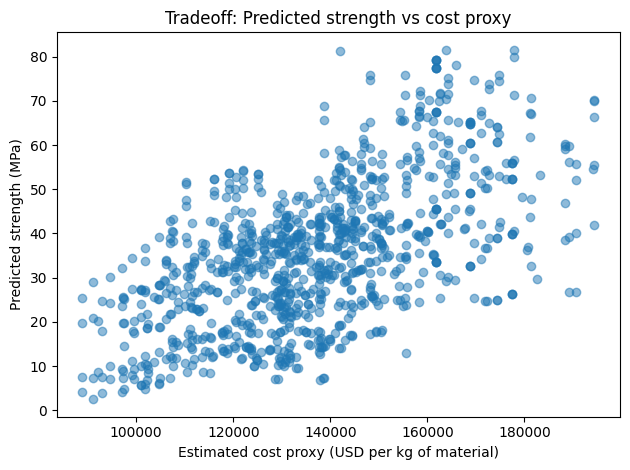

Saved: /content/drive/MyDrive/Indigo Research Project/figures/tradeoff_strength_vs_cost_proxy.png


In [ ]:
# Plots results of previous cell
plt.figure()
plt.scatter(df_proxy["co2_proxy_kg"], df_proxy["pred_strength_mpa"], alpha=0.5)
plt.xlabel("Estimated CO₂ proxy (kg CO₂e per kg of material)")
plt.ylabel("Predicted strength (MPa)")
plt.title("Tradeoff: Predicted strength vs CO₂ proxy")
plt.tight_layout()
t1 = os.path.join(FIG_DIR, "tradeoff_strength_vs_co2_proxy.png")
plt.savefig(t1, dpi=200)
plt.show()
print("Saved:", t1)

plt.figure()
plt.scatter(df_proxy["cost_proxy_USD"], df_proxy["pred_strength_mpa"], alpha=0.5)
plt.xlabel("Estimated cost proxy (USD per kg of material)")
plt.ylabel("Predicted strength (MPa)")
plt.title("Tradeoff: Predicted strength vs cost proxy")
plt.tight_layout()
t2 = os.path.join(FIG_DIR, "tradeoff_strength_vs_cost_proxy.png")
plt.savefig(t2, dpi=200)
plt.show()
print("Saved:", t2)


**Tradeoff Scatterplots (Proxy Analysis):** Although a positive relationship exists between increasing cost/CO₂ and increasing concrete compressive strength, it is clear a non-linear relationship exists between cost/CO₂ and predicted strength. This indicates that there are many different mixtures to optimize either factor based on the chosen features.

## 9) Method Overview

**Dataset:** Concrete Compressive Strength dataset (Kaggle) with mixture composition features (kg/m³) and curing age (days).  
**Target:** compressive strength (MPa).  
**Models:** linear regression baseline, random forest, and gradient boosting.  
**Evaluation:** 5-fold cross-validation on the training set and final performance on a held-out test set using R² and mean absolute error (MAE).  
**Tuning:** small grid search over key hyperparameters for tree-based models.  
**Interpretation:** permutation importance computed on the test set for the best-performing model.  

Label any CO₂ and cost quantities as **proxy estimates** unless replaced by cited lifecycle data.
